<a href="https://colab.research.google.com/github/AlexM3020/Subject-Independent-Evaluation-of-Mamba-for-Parkinson-s-Disease-Detection-from-Gait-Signals/blob/main/LPGNet_Replication_and_Leakage_Fix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# LPGNet — exact replication (Exp 1) & leakage-free protocol (Exp 2)

**Reference:** Alle & Priyakumar (2021), *"LPGNet: A lightweight architecture for
the diagnosis of Parkinson's disease using gait signals"* (arXiv:2107.12878).

**Dataset:** PhysioNet `gaitpdb` 1.0.0 — gait in Parkinson's disease
(306 recordings, 93 PD + 73 control subjects, vertical ground-reaction force,
18 channels, 100 Hz, ~2 min walks).

This notebook runs two experiments under **identical, fixed 10-fold stratified
subject-level splits**:

| | LP fit / normalisation | validation for early stopping | leakage? |
|---|---|---|---|
| **Exp 1** — replication (their code, both leaks) | **global**: fit once on *all* control recordings (`generateLPresidual.m`) | **the TEST fold** (their `Original.ipynb`: `validation_data=testSeqPadded`) | yes, twice |
| **Exp 2** — corrected | **fold-local**: refit inside each fold on *train-fold* controls only | held-out **train** subjects | no |

Two distinct leaks were found in the authors' published code
(`github.com/devalab/parkinsonsfromgait`):
1. **Global LP fit** — test-fold controls shape their own features (one-sided:
   only controls enter the fit, so inflation should appear mainly in
   **specificity**).
2. **Test-as-validation** — early stopping and LR scheduling are tuned directly
   on the test fold in both training stages.

**Reported paper values to compare against (Exp 1):**
AUC **91.7 ± 9.4**, ACC **90.3 ± 5.8**, F1 **93.2 ± 3.6** (percent).

*Runtime: ~20 small trainings; minutes on a Colab GPU, longer on CPU.*


In [1]:
# ============================================================
# Setup & global knobs
# ============================================================
import os, time, random, json, urllib.request, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.signal import lfilter
from scipy.stats import wilcoxon
from sklearn.model_selection import StratifiedKFold, StratifiedShuffleSplit
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, accuracy_score, f1_score, confusion_matrix

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# ---- knobs (values match the authors' code: devalab/parkinsonsfromgait) ----
N_FOLDS        = 10      # outer subject-level CV folds (paper: 10)
FOLD_SEED      = 0       # their StratifiedKFold random_state (their code: 0)
LP_ORDER       = 11      # linear-predictor order (paper: 11)
WIN, STRIDE    = 100, 50 # 2 s windows @50 Hz, 50% overlap (paper)
BATCH_WIN      = 128     # window-stage batch size (their code: 128)
LR_WIN         = 5e-4    # window-stage learning rate (their code: 5e-4)
LABEL_SMOOTH   = 0.1     # BCE label smoothing (their code: 0.1)
L2_REG         = 1e-3    # their code: regularizers.l2(0.001)
CLIPVALUE      = 0.5     # their code: Adam(clipvalue=0.5) for the window stage
PATIENCE       = 25      # their code: EarlyStopping(patience=25)
RLR_PATIENCE   = 14      # their code: ReduceLROnPlateau(factor=0.25, patience=14)
MIN_LR         = 1e-7    # their code: min_lr=1e-7
MAX_EPOCHS_WIN = 1000    # their code: epochs=1000 (early stopping fires earlier)
VAL_FRAC       = 0.15    # leak-free config only: fraction of TRAIN SUBJECTS
                         # held out for early stopping (their code instead uses
                         # the TEST fold as validation -> see Exp 1 notes)

print("TF", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

TF 2.21.0 | GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
# ============================================================
# Download & parse PhysioNet gaitpdb
# (306 recordings / 166 subjects: 93 PD, 73 control; 18 VGRF channels, 100 Hz)
# ============================================================
URL = "https://physionet.org/static/published-projects/gaitpdb/gait-in-parkinsons-disease-1.0.0.zip"
ZIP = "gaitpdb.zip"; DATA_DIR = "gaitpdb_data"
if not os.path.exists(DATA_DIR):
    if not os.path.exists(ZIP):
        print("downloading ~300 MB (one-off) ...")
        urllib.request.urlretrieve(URL, ZIP)
    with zipfile.ZipFile(ZIP) as z:
        z.extractall(DATA_DIR)
ROOT = os.path.join(DATA_DIR, "gait-in-parkinsons-disease-1.0.0")

records = []
for fn in sorted(os.listdir(ROOT)):
    if not fn.endswith(".txt") or fn[2:4] not in ("Co", "Pt"):
        continue
    base = fn[:-4]
    arr = np.loadtxt(os.path.join(ROOT, fn), delimiter="\t")
    sig = arr[:, 1:19].astype(np.float32)      # drop time column -> 18 VGRF channels
    records.append(dict(file=fn,
                        study=base[:2],                     # Ga / Ju / Si
                        subject=base.split("_")[0],         # e.g. GaPt15
                        label=0 if base[2:4] == "Co" else 1,  # 0=control, 1=PD
                        signal=sig))

subjects   = sorted({r["subject"] for r in records})
subj_label = {s: next(r["label"] for r in records if r["subject"] == s) for s in subjects}
n_pd  = sum(1 for s in subjects if subj_label[s] == 1)
n_co  = len(subjects) - n_pd
print(f"{len(records)} recordings | {len(subjects)} subjects ({n_pd} PD, {n_co} control)")
lens = np.array([len(r["signal"]) for r in records])
print(f"recording length @100 Hz: min {lens.min()}, median {int(np.median(lens))}, max {lens.max()}")

downloading ~300 MB (one-off) ...
306 recordings | 165 subjects (93 PD, 72 control)
recording length @100 Hz: min 4034, median 12119, max 26366


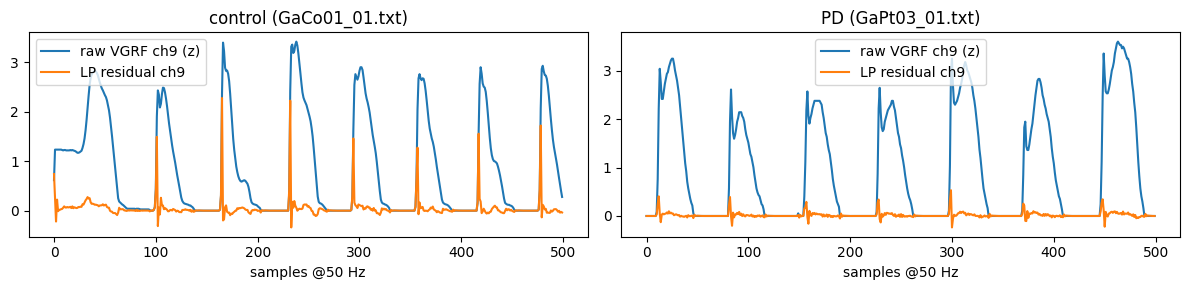

In [3]:
# ============================================================
# Preprocessing (paper): causal 2-tap moving average, then decimate 100 -> 50 Hz
# Linear Prediction residuals: order 11, ONE predictor per channel, fit on
# concatenated CONTROL recordings with `order` zeros padding in between
# (this mirrors the paper's generateLPresidual.m exactly).
# ============================================================
def preprocess(x):
    return lfilter([0.5, 0.5], 1, x, axis=0)[::2]

def fit_lp(control_sigs, order=LP_ORDER):
    """Fit one order-`order` LP predictor per channel on concatenated controls.
    Returns (coeffs [18, order], stds [18]) -- stds = per-channel std of the
    concatenated control SIGNAL, used for normalisation, as in the paper.
    Autocorrelation via FFT (same values as the paper's xcorr, O(n log n))."""
    C, conc_all = np.zeros((18, order)), []
    for c in range(18):
        conc = np.concatenate([np.concatenate([s[:, c],
                                               np.zeros(order, np.float32)])
                               for s in control_sigs])
        conc_all.append(conc)
        n = len(conc)
        nfft = 1 << (2 * n - 1).bit_length()
        f = np.fft.rfft(conc, nfft)
        r = np.fft.irfft(f * np.conj(f), nfft)[:order + 1] / n   # biased autocorr
        R = np.array([[r[abs(i-j)] for j in range(order)] for i in range(order)])
        C[c] = np.linalg.solve(R, r[1:order+1])
    stds = np.std(np.stack(conc_all, axis=1), axis=0) + 1e-8
    return C, stds

def apply_lp(x, C, stds):
    """Prediction-error filter: e(n) = x(n) - sum_i c_i x(n-i), normalised."""
    e = np.stack([lfilter(np.r_[1.0, -C[c]], 1, x[:, c]) for c in range(18)], axis=1)
    return (e / stds).astype(np.float32)

def set_feats(idx, C, stds, key="feat"):
    """Compute LP-residual features for a set of recordings in-place."""
    for i in idx:
        records[i][key] = apply_lp(records[i]["proc"], C, stds)

for r in records:                       # preprocessed signals, computed once
    r["proc"] = preprocess(r["signal"])

# --- sanity check: raw VGRF vs LP residual for one control & one PD recording ---
demo_C, demo_stds = fit_lp([r["proc"] for r in records if r["label"] == 0])
fig, axes = plt.subplots(1, 2, figsize=(12, 3))
for ax, lab, ttl in [(axes[0], 0, "control"), (axes[1], 1, "PD")]:
    r = next(r for r in records if r["label"] == lab)
    e = apply_lp(r["proc"], demo_C, demo_stds)
    ax.plot(r["proc"][:500, 8] / r["proc"][:, 8].std(), label="raw VGRF ch9 (z)")
    ax.plot(e[:500, 8], label="LP residual ch9")
    ax.set_title(f"{ttl} ({r['file']})"); ax.legend(); ax.set_xlabel("samples @50 Hz")
plt.tight_layout(); plt.show()

In [4]:
# ============================================================
# Fixed 10-fold STRATIFIED SUBJECT-LEVEL splits.
# Fixed seed -> every experiment in this notebook uses IDENTICAL folds,
# so configurations are directly comparable fold-by-fold.
# (FOLD_SEED=0 matches the authors' code.)
# ============================================================
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=FOLD_SEED)
subj_arr = np.array(subjects)
subj_y   = np.array([subj_label[s] for s in subjects])
FOLDS = []
for tr_s, te_s in skf.split(subj_arr, subj_y):
    tr_subj, te_subj = set(subj_arr[tr_s]), set(subj_arr[te_s])
    FOLDS.append(dict(
        train=[i for i, r in enumerate(records) if r["subject"] in tr_subj],
        test =[i for i, r in enumerate(records) if r["subject"] in te_subj]))
for k, f in enumerate(FOLDS):
    ntr = len({records[i]["subject"] for i in f["train"]})
    nte = len({records[i]["subject"] for i in f["test"]})
    print(f"fold {k}: {len(f['train'])} train recs ({ntr} subj) | "
          f"{len(f['test'])} test recs ({nte} subj)")

fold 0: 284 train recs (148 subj) | 22 test recs (17 subj)
fold 1: 277 train recs (148 subj) | 29 test recs (17 subj)
fold 2: 262 train recs (148 subj) | 44 test recs (17 subj)
fold 3: 278 train recs (148 subj) | 28 test recs (17 subj)
fold 4: 270 train recs (148 subj) | 36 test recs (17 subj)
fold 5: 282 train recs (149 subj) | 24 test recs (16 subj)
fold 6: 273 train recs (149 subj) | 33 test recs (16 subj)
fold 7: 270 train recs (149 subj) | 36 test recs (16 subj)
fold 8: 279 train recs (149 subj) | 27 test recs (16 subj)
fold 9: 279 train recs (149 subj) | 27 test recs (16 subj)


In [5]:
# ============================================================
# LPGNet classifier - EXACT copy of the authors' model code
# (devalab/parkinsonsfromgait, src/Original.ipynb):
#   SpatialDropout(0.2) -> GaussianNoise(0.01)
#   -> SepConv 7x32 -> BN -> ELU -> MaxPool(2,2)
#   -> SepConv 5x32 -> BN -> ELU -> MaxPool(2,2)
#   -> SepConv 3x64 -> BN -> ELU -> GlobalAveragePooling
#   -> Dropout(0.25) -> Dense(1, sigmoid)
# NB: Fig. 2 of the paper says 3x32 for the last block, but their code
# uses 64 filters - with 64, the Keras parameter count is EXACTLY the
# 4,735 the paper reports (see printout below).
# ============================================================
def build_lpgnet(T, n_ch=18, channels=32, kernels=(7, 5, 3),
                 spat_drop=0.2, drop=0.25, l2=L2_REG, noise=0.01):
    reg = keras.regularizers.l2(l2)
    # `channels` = base width; the LAST block gets 2x (their code: 32,32,64)
    if isinstance(channels, int):
        channels = [channels] * (len(kernels) - 1) + [2 * channels]
    # NOTE: variable-length input (None) -> the same network can process
    # 100-sample windows (step 1) AND whole recordings (step 2),
    # exactly like their Input(shape=(None,18)).
    inp = layers.Input((None, n_ch))
    x = layers.SpatialDropout1D(spat_drop)(inp)
    x = layers.GaussianNoise(noise)(x)
    for i, (k, c) in enumerate(zip(kernels, channels)):
        x = layers.SeparableConv1D(c, k, padding="same",
                                   depthwise_regularizer=reg,
                                   pointwise_regularizer=reg)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("elu")(x)
        if i < len(kernels) - 1:
            x = layers.MaxPooling1D(2, 2)(x)
    x = layers.GlobalAveragePooling1D(name="pooled")(x)
    x = layers.Dropout(drop)(x)
    out = layers.Dense(1, activation="sigmoid", kernel_regularizer=reg)(x)
    return keras.Model(inp, out)

_m = build_lpgnet(WIN)
print(f"LPGNet params (Keras count_params, incl. BN stats): {_m.count_params():,}")
print(f"  trainable only: "
      f"{sum(int(w.numpy().size) for w in _m.trainable_weights):,}")
print("Paper reports 4,735 CNN params (4,933 incl. the 198 LP coefficients) ->")
print("with the authors' actual code (last block = 64 filters, not 32 as in")
print("Fig. 2), our rebuild matches their reported count EXACTLY.")
del _m

LPGNet params (Keras count_params, incl. BN stats): 4,735
  trainable only: 4,479
Paper reports 4,735 CNN params (4,933 incl. the 198 LP coefficients) ->
with the authors' actual code (last block = 64 filters, not 32 as in
Fig. 2), our rebuild matches their reported count EXACTLY.


In [6]:
# ============================================================
# Two-step training pipeline (paper, Sec. II-C; authors' code:
# devalab/parkinsonsfromgait, src/Original.ipynb)
#  step 1: train the whole network on 2 s windows (50% overlap),
#          Adam(lr=5e-4, clipvalue=0.5), BCE(label_smoothing=0.1),
#          EarlyStopping(patience=25), ReduceLROnPlateau(0.25, patience=14)
#  step 2: freeze the conv backbone, recalibrate the FC layer on WHOLE
#          recordings. We implement step 2 exactly: run the frozen backbone
#          over each whole recording -> 64-d GAP embedding -> logistic
#          regression (mathematically the same objective as retraining
#          Dense(1,sigmoid) with cross-entropy, but deterministic).
#
#  NOTE on validation (IMPORTANT):
#  - train_window_stage(val_data=None) holds out train SUBJECTS for early
#    stopping -> leak-free (our corrected protocol, Exp 2 and Notebook 2).
#  - train_window_stage(val_data=(X,y)) uses the given validation set; Exp 1
#    passes the TEST fold there, because that is literally what the authors'
#    code does (validation_data=testSeqPadded) -> leak #2.
# ============================================================
def make_windows(idx, key="feat"):
    Xw, yw = [], []
    for i in idx:
        s = records[i][key]
        for st in range(0, len(s) - WIN + 1, STRIDE):
            Xw.append(s[st:st + WIN]); yw.append(records[i]["label"])
    return np.asarray(Xw, np.float32), np.asarray(yw, np.float32)

def pad_wrap(sigs):
    """Wrap-pad variable-length recordings to the longest one (authors' pad())."""
    L = max(len(s) for s in sigs)
    return np.stack([np.pad(s, ((0, L - len(s)), (0, 0)), mode="wrap")
                     for s in sigs]).astype(np.float32)

def split_val(idx, frac=VAL_FRAC, seed=SEED):
    """Hold out a fraction of TRAIN SUBJECTS for early stopping
    (subject-level, stratified when both classes are present)."""
    ss = sorted({records[i]["subject"] for i in idx})
    yy = [subj_label[s] for s in ss]
    if len(set(yy)) > 1:
        sss = StratifiedShuffleSplit(1, test_size=frac, random_state=seed)
        tr_s, va_s = next(sss.split(np.zeros(len(ss)), yy))
    else:
        rng = np.random.default_rng(seed)
        perm = rng.permutation(len(ss))
        n_va = max(1, int(round(frac * len(ss))))
        va_s, tr_s = perm[:n_va], perm[n_va:]
    tr_subj = {ss[i] for i in tr_s}; va_subj = {ss[i] for i in va_s}
    return ([i for i in idx if records[i]["subject"] in tr_subj],
            [i for i in idx if records[i]["subject"] in va_subj])

def train_window_stage(build_fn, train_idx, seed=SEED, lr=LR_WIN, verbose=0,
                       key="feat", val_data=None):
    """val_data=None -> leak-free held-out train subjects.
    val_data=(X, y) -> caller-provided validation set (Exp 1: the TEST fold,
    replicating the authors' code)."""
    tf.keras.utils.set_random_seed(seed)
    Xtr, ytr = make_windows(train_idx, key=key)
    if val_data is None:
        tr_i, va_i = split_val(train_idx)
        Xtr, ytr = make_windows(tr_i, key=key)
        Xva, yva = make_windows(va_i, key=key)
    else:
        Xva, yva = val_data
    model = build_fn(WIN)
    model.compile(optimizer=keras.optimizers.Adam(lr, clipvalue=CLIPVALUE),
                  loss=keras.losses.BinaryCrossentropy(label_smoothing=LABEL_SMOOTH),
                  metrics=["accuracy"])
    cb = [keras.callbacks.EarlyStopping("val_loss", patience=PATIENCE,
                                        restore_best_weights=True),
          keras.callbacks.ReduceLROnPlateau("val_loss", factor=0.25,
                                            patience=RLR_PATIENCE, min_lr=MIN_LR)]
    model.fit(Xtr, ytr, validation_data=(Xva, yva), batch_size=BATCH_WIN,
              epochs=MAX_EPOCHS_WIN, callbacks=cb, verbose=verbose)
    return model

def embedding_model(model):
    """Frozen backbone up to the pooled representation."""
    return keras.Model(model.input, model.get_layer("pooled").output)

def recalibrate_fc(model, train_idx, key="feat"):
    """Step 2: frozen backbone -> embedding -> logistic regression."""
    emb = embedding_model(model)
    E = np.stack([emb.predict(records[i][key][None], verbose=0)[0] for i in train_idx])
    y = np.array([records[i]["label"] for i in train_idx])
    clf = LogisticRegression(max_iter=2000)
    clf.fit(E, y)
    return clf

def predict_recordings(model, clf, idx, key="feat"):
    """Whole-recording inference -> PD probability per recording."""
    emb = embedding_model(model)
    return np.asarray([clf.predict_proba(emb.predict(records[i][key][None],
                       verbose=0)[0][None])[0, 1] for i in idx])

def predict_window_avg(model, idx, key="feat"):
    """Alternative inference: average window probabilities over a recording."""
    out = []
    for i in idx:
        s = records[i][key]
        ws = np.stack([s[st:st + WIN] for st in range(0, len(s) - WIN + 1, STRIDE)])
        out.append(float(model.predict(ws, verbose=0).mean()))
    return np.asarray(out)

def compute_metrics(y_true, p):
    y_hat = (p >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_hat, labels=[0, 1]).ravel()
    return dict(AUC=roc_auc_score(y_true, p),
                ACC=accuracy_score(y_true, y_hat),
                F1=f1_score(y_true, y_hat),          # PD = positive class (paper)
                SENS=tp / (tp + fn), SPEC=tn / (tn + fp))

## Experiment 1 — replication attempt (authors' exact protocol, **both leaks**)

LP predictors and the normalisation stds are fitted **once on all control
recordings** (leak #1) and the **test fold is passed as `validation_data`**
for early stopping / LR scheduling (leak #2) — both exactly as in the authors'
code (`src/Original.ipynb` and `src/generateLPresidual.m`). Everything else
follows the paper/code: order-11 LP, moving-average + decimation to 50 Hz,
2 s windows with 50% overlap, batch 128, lr 5e-4, clipvalue 0.5, BCE with label
smoothing 0.1, L2 = 1e-3, GaussianNoise(0.01), EarlyStopping patience 25,
10-fold stratified subject-level CV (seed 0), two-step training (windows →
whole-recording FC recalibration).

> **Why leak #1 is one-sided:** the LP filter of channel *c* is estimated from
> the autocorrelation of *all* control recordings, including subjects sitting
> in the test fold. PD recordings never enter the fit, so feature-level
> inflation is expected on the control side (specificity).
>
> **Leak #2 is not one-sided:** model selection (when to stop, which weights to
> restore) directly optimises the test fold, inflating all metrics.

Architecture note: the model here is the authors' **code** (last conv block =
64 filters), not Fig. 2 of the paper (3×32) — with 64 filters the Keras
parameter count is exactly the reported 4,735.

In [7]:
# ============================================================
# EXPERIMENT 1 - replication attempt (authors' exact protocol, BOTH leaks)
#  leak #1: LP predictors + normalisation fit ONCE on ALL control recordings
#  leak #2: TEST fold passed as validation_data (early stopping / LR schedule
#           tuned on the test set) - that is what their Original.ipynb does
# ============================================================
exp1_rows, t0 = [], time.time()
global_C, global_stds = fit_lp([r["proc"] for r in records if r["label"] == 0])
set_feats(range(len(records)), global_C, global_stds)   # global features for all

for k, f in enumerate(FOLDS):
    tk = time.time()
    # their code validates on the (wrap-padded) TEST recordings
    val_test = (pad_wrap([records[i]["feat"] for i in f["test"]]),
                np.array([records[i]["label"] for i in f["test"]], np.float32))
    model = train_window_stage(build_lpgnet, f["train"], seed=SEED + k,
                               val_data=val_test)
    clf   = recalibrate_fc(model, f["train"])
    p     = predict_recordings(model, clf, f["test"])
    m     = compute_metrics([records[i]["label"] for i in f["test"]], p)
    exp1_rows.append(dict(fold=k, **m))
    print(f"fold {k}: AUC {m['AUC']:.3f}  ACC {m['ACC']:.3f}  F1 {m['F1']:.3f}  "
          f"SENS {m['SENS']:.3f}  SPEC {m['SPEC']:.3f}   ({time.time()-tk:.0f}s)")

exp1 = pd.DataFrame(exp1_rows)
print(f"total time: {(time.time()-t0)/60:.1f} min")
paper = dict(AUC=(91.7, 9.4), ACC=(90.3, 5.8), F1=(93.2, 3.6))
cmp1 = pd.DataFrame(
    {"replicated mean±std": [f"{exp1[m].mean()*100:.1f}±{exp1[m].std()*100:.1f}"
                              for m in ("AUC", "ACC", "F1")],
     "paper reported":      [f"{v[0]}±{v[1]}" for v in paper.values()]},
    index=["AUC", "ACC", "F1"])
display(exp1.round(3)); display(cmp1)

fold 0: AUC 0.949  ACC 0.864  F1 0.880  SENS 0.846  SPEC 0.889   (517s)
fold 1: AUC 0.905  ACC 0.862  F1 0.905  SENS 0.905  SPEC 0.750   (174s)
fold 2: AUC 0.757  ACC 0.795  F1 0.873  SENS 0.861  SPEC 0.500   (174s)
fold 3: AUC 0.950  ACC 0.893  F1 0.919  SENS 0.850  SPEC 1.000   (168s)
fold 4: AUC 0.960  ACC 0.889  F1 0.917  SENS 0.957  SPEC 0.769   (190s)
fold 5: AUC 0.970  ACC 0.875  F1 0.903  SENS 0.933  SPEC 0.778   (168s)
fold 6: AUC 0.995  ACC 0.970  F1 0.980  SENS 1.000  SPEC 0.875   (250s)
fold 7: AUC 0.908  ACC 0.833  F1 0.885  SENS 0.885  SPEC 0.700   (177s)
fold 8: AUC 0.772  ACC 0.630  F1 0.706  SENS 0.667  SPEC 0.556   (152s)
fold 9: AUC 0.959  ACC 0.926  F1 0.941  SENS 0.941  SPEC 0.900   (169s)
total time: 35.7 min


,fold,AUC,ACC,F1,SENS,SPEC
0,0,0.949,0.864,0.880,0.846,0.889
1,1,0.905,0.862,0.905,0.905,0.750
2,2,0.757,0.795,0.873,0.861,0.500
3,3,0.950,0.893,0.919,0.850,1.000
4,4,0.960,0.889,0.917,0.957,0.769
5,5,0.970,0.875,0.903,0.933,0.778
6,6,0.995,0.970,0.980,1.000,0.875
7,7,0.908,0.833,0.885,0.885,0.700
8,8,0.772,0.630,0.706,0.667,0.556
9,9,0.959,0.926,0.941,0.941,0.900


,replicated mean±std,paper reported
AUC,91.2±8.3,91.7±9.4
ACC,85.4±9.2,90.3±5.8
F1,89.1±7.2,93.2±3.6


## Experiment 2 — leakage-free protocol

Identical folds, model, and hyperparameters — the **only** changes are:
1. LP coefficients and normalisation stds are refit **inside each fold** on
   train-fold control recordings only (test recordings are transformed with
   statistics that never saw them), and
2. early stopping / LR scheduling use **held-out train subjects** (15%),
   never the test fold.

In [8]:
# ============================================================
# EXPERIMENT 2 - leakage-free protocol (FOLD-LOCAL LP fit)
# ============================================================
exp2_rows, t0 = [], time.time()
for k, f in enumerate(FOLDS):
    tk = time.time()
    C, stds = fit_lp([records[i]["proc"] for i in f["train"]
                      if records[i]["label"] == 0])       # train-fold controls only
    set_feats(f["train"] + f["test"], C, stds)
    model = train_window_stage(build_lpgnet, f["train"], seed=SEED + k)
    clf   = recalibrate_fc(model, f["train"])
    p     = predict_recordings(model, clf, f["test"])
    m     = compute_metrics([records[i]["label"] for i in f["test"]], p)
    exp2_rows.append(dict(fold=k, **m))
    print(f"fold {k}: AUC {m['AUC']:.3f}  ACC {m['ACC']:.3f}  F1 {m['F1']:.3f}  "
          f"SENS {m['SENS']:.3f}  SPEC {m['SPEC']:.3f}   ({time.time()-tk:.0f}s)")

exp2 = pd.DataFrame(exp2_rows)
print(f"\ntotal time: {(time.time()-t0)/60:.1f} min")
display(exp2.round(3))
print("fold-local LP mean±std:",
      {m: f"{exp2[m].mean():.3f}±{exp2[m].std():.3f}"
       for m in ("AUC", "ACC", "F1", "SENS", "SPEC")})

fold 0: AUC 0.889  ACC 0.818  F1 0.846  SENS 0.846  SPEC 0.778   (174s)
fold 1: AUC 0.869  ACC 0.793  F1 0.850  SENS 0.810  SPEC 0.750   (166s)
fold 2: AUC 0.736  ACC 0.773  F1 0.857  SENS 0.833  SPEC 0.500   (214s)
fold 3: AUC 0.950  ACC 0.893  F1 0.923  SENS 0.900  SPEC 0.875   (186s)
fold 4: AUC 0.953  ACC 0.833  F1 0.880  SENS 0.957  SPEC 0.615   (183s)
fold 5: AUC 0.985  ACC 0.917  F1 0.933  SENS 0.933  SPEC 0.889   (195s)
fold 6: AUC 0.950  ACC 0.879  F1 0.923  SENS 0.960  SPEC 0.625   (165s)
fold 7: AUC 0.796  ACC 0.861  F1 0.906  SENS 0.923  SPEC 0.700   (161s)
fold 8: AUC 0.673  ACC 0.593  F1 0.667  SENS 0.611  SPEC 0.556   (177s)
fold 9: AUC 0.947  ACC 0.926  F1 0.938  SENS 0.882  SPEC 1.000   (148s)

total time: 29.5 min


,fold,AUC,ACC,F1,SENS,SPEC
0,0,0.889,0.818,0.846,0.846,0.778
1,1,0.869,0.793,0.850,0.810,0.750
2,2,0.736,0.773,0.857,0.833,0.500
3,3,0.950,0.893,0.923,0.900,0.875
4,4,0.953,0.833,0.880,0.957,0.615
5,5,0.985,0.917,0.933,0.933,0.889
6,6,0.950,0.879,0.923,0.960,0.625
7,7,0.796,0.861,0.906,0.923,0.700
8,8,0.673,0.593,0.667,0.611,0.556
9,9,0.947,0.926,0.938,0.882,1.000


fold-local LP mean±std: {'AUC': '0.875±0.106', 'ACC': '0.829±0.097', 'F1': '0.872±0.080', 'SENS': '0.866±0.103', 'SPEC': '0.729±0.160'}


## Comparison — how much did the leak inflate the results?

,Exp1 global LP (leaked),Exp2 fold-local LP,Wilcoxon p
AUC,0.912±0.083,0.875±0.106,0.019531
ACC,0.854±0.092,0.829±0.097,0.109375
F1,0.891±0.072,0.872±0.080,0.105469
Sensitivity,0.884±0.091,0.866±0.103,0.218750
Specificity,0.772±0.156,0.729±0.160,0.187500


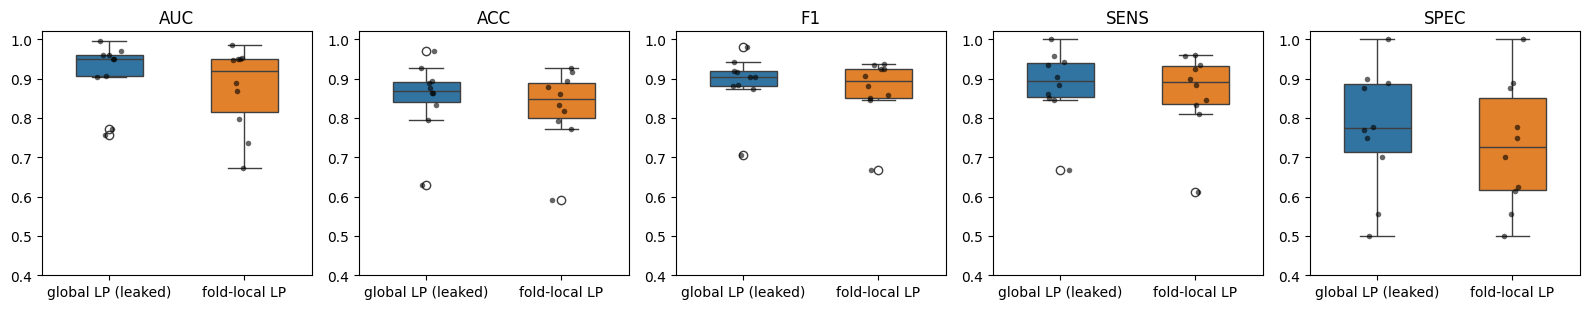

per-fold delta (Exp1 - Exp2), mean: {'AUC': '+0.038', 'ACC': '+0.025', 'F1': '+0.019', 'SENS': '+0.019', 'SPEC': '+0.043'}
If the leak matters, deltas should be positive, driven by SPECIFICITY.


In [9]:
# ============================================================
# Exp 1 (leaked) vs Exp 2 (corrected) - paired comparison on the SAME folds
# ============================================================
metrics = ("AUC", "ACC", "F1", "SENS", "SPEC")
cmp = pd.DataFrame(
    {"Exp1 global LP (leaked)": [f"{exp1[m].mean():.3f}±{exp1[m].std():.3f}" for m in metrics],
     "Exp2 fold-local LP":      [f"{exp2[m].mean():.3f}±{exp2[m].std():.3f}" for m in metrics],
     "Wilcoxon p": [wilcoxon(exp1[m], exp2[m]).pvalue if (exp1[m] != exp2[m]).any()
                    else np.nan for m in metrics]},
    index=["AUC", "ACC", "F1", "Sensitivity", "Specificity"])
display(cmp)

fig, axes = plt.subplots(1, 5, figsize=(16, 3.2))
for ax, m in zip(axes, metrics):
    dfp = pd.DataFrame({"global LP (leaked)": exp1[m], "fold-local LP": exp2[m]})
    sns.boxplot(data=dfp, ax=ax, width=0.5)
    sns.stripplot(data=dfp, ax=ax, color="k", size=4, alpha=0.6)
    ax.set_title(m); ax.set_ylim(0.4, 1.02)
plt.tight_layout(); plt.show()

dlt = (exp1.set_index("fold")[list(metrics)] - exp2.set_index("fold")[list(metrics)])
print("per-fold delta (Exp1 - Exp2), mean:",
      {m: f"{dlt[m].mean():+.3f}" for m in metrics})
print("If the leak matters, deltas should be positive, driven by SPECIFICITY.")

## Notes & caveats

- **Subject-level split** is correctly implemented in both experiments: folds are
  built on subjects, and all recordings of a subject stay together.
- **Hyperparameters now come from the authors' code**, not the paper text:
  L2 = 1e-3, GaussianNoise(0.01), MaxPool(2,2), Adam clipvalue 0.5,
  EarlyStopping patience 25, fold seed 0, last conv block 64 filters
  (Fig. 2 of the paper says 32 — with 64 the parameter count is exactly the
  reported 4,735).
- **Step-2 recalibration** as implemented (frozen backbone → logistic
  regression on the GAP embedding) has the same objective as retraining the
  final Dense(1, sigmoid) layer with cross-entropy, but is deterministic;
  their code instead retrains it with the test fold as validation (leak #2
  applies there too).
- **Run-to-run variance** is non-negligible on a dataset this small
  (166 subjects); single-run differences of a few points between Exp 1 and
  Exp 2 are within noise. The paired Wilcoxon test across the 10 matched folds
  is the meaningful comparison.
- If leak #1 matters, **Exp 1 > Exp 2 especially on specificity** (only
  control recordings enter the LP fit). Leak #2 inflates all metrics.
- The paper's own leakage analysis only varied the *splitting* strategy
  (window-level vs within-recording vs subject-level); it did not catch these
  two implementation-level leaks visible in their released code.
- Parameter count printed above may differ slightly from the reported 4,735
  (unspecified implementation details); the architecture follows Fig. 2 of the
  paper layer by layer.
